In [1]:
import sys, time
sys.path.insert(0, "../examples")
import numpy as np, jax.numpy as jnp, scipy.optimize
import matplotlib.pyplot as plt
import gebtaero_jax as gx
from gebtaero_jax import tracking as tk
from pazy_wing import PazyWing, load_reference, SEMISPAN

wing = PazyWing()                       # skin model, no tip mass, 15 beam elements, Peters inflow
EXP = {"onset": {3: 49, 5: 43, 7: 38}, "offset": {3: 55, 5: 48}}                    # Ritter et al., Table 4
LDWG = {"onset": {3: (47.7, 1.2), 5: (41.8, 0.7), 7: (37.9, 1.1)}, "offset": {3: (58.4, 2.5), 5: (48.6, 1.9), 7: (43.5, 2.2)}}

## 1. Beam model and wind-off modes
Per element: 4×4 stiffness (axial, torsion, out-of-plane, in-plane) with couplings, transverse shear rigid. Per node: lumped mass with CG
offset and inertia, converted to sectional mass matrices. The spanwise lift slope (5.6 /rad at the root, falling to 0 at the tip) comes
from the same repository.

In [2]:
m0, f0 = wing.build(aero=gx.Aero.NONE)
res0 = gx.modal_analysis(m0, f0)
f_ours = res0.table(5)[:, 1]
f_um = load_reference("umnast_frequencies_undeformed.txt")
f_gfem = np.array([4.19, 28.47, 40.74, 82.39, 104.78])  # Ritter et al., Fig. 8 (built-up FEM with skin)
names = ["1st OOP", "2nd OOP", "1st torsion", "3rd OOP", "1st IP"]
print(f"total mass {wing.total_mass():.4f} kg, {m0.n_el} elements, {wing.build()[0].n_dof} unknowns with Peters inflow\n")
print(f"{'mode':12s} {'gebtaero-jax':>12s} {'UM/NAST beam':>12s} {'built-up FEM':>12s}")
for n, a, b, c in zip(names, f_ours, f_um, f_gfem):
    print(f"{n:12s} {a:12.2f} {b:12.2f} {c:12.2f}")

total mass 0.3566 kg, 15 elements, 372 unknowns with Peters inflow

mode         gebtaero-jax UM/NAST beam built-up FEM
1st OOP              4.19         4.19         4.19
2nd OOP             28.49        28.49        28.47
1st torsion         42.01        41.88        40.74
3rd OOP             83.10        83.06        82.39
1st IP             105.89       105.89       104.78


Same beam data, different geometrically exact formulation (GEBT mixed form vs. UM/NAST strain-based): the frequencies agree to 0.3 %.

## 2. Static aeroelastic deflection
Root angle of attack fixed, speed increased, no gravity (the wing is mounted vertically), equilibrium continued from one speed to the next.

3 sweeps x 30 speeds in 7.7 s
AoA 5°, U = 30 m/s: tip z =  10.2 %  (UM/NAST   9.9 %)
AoA 5°, U = 50 m/s: tip z =  30.4 %  (UM/NAST  30.4 %)
AoA 7°, U = 30 m/s: tip z =  14.0 %  (UM/NAST  13.6 %)
AoA 7°, U = 50 m/s: tip z =  38.5 %  (UM/NAST  38.9 %)


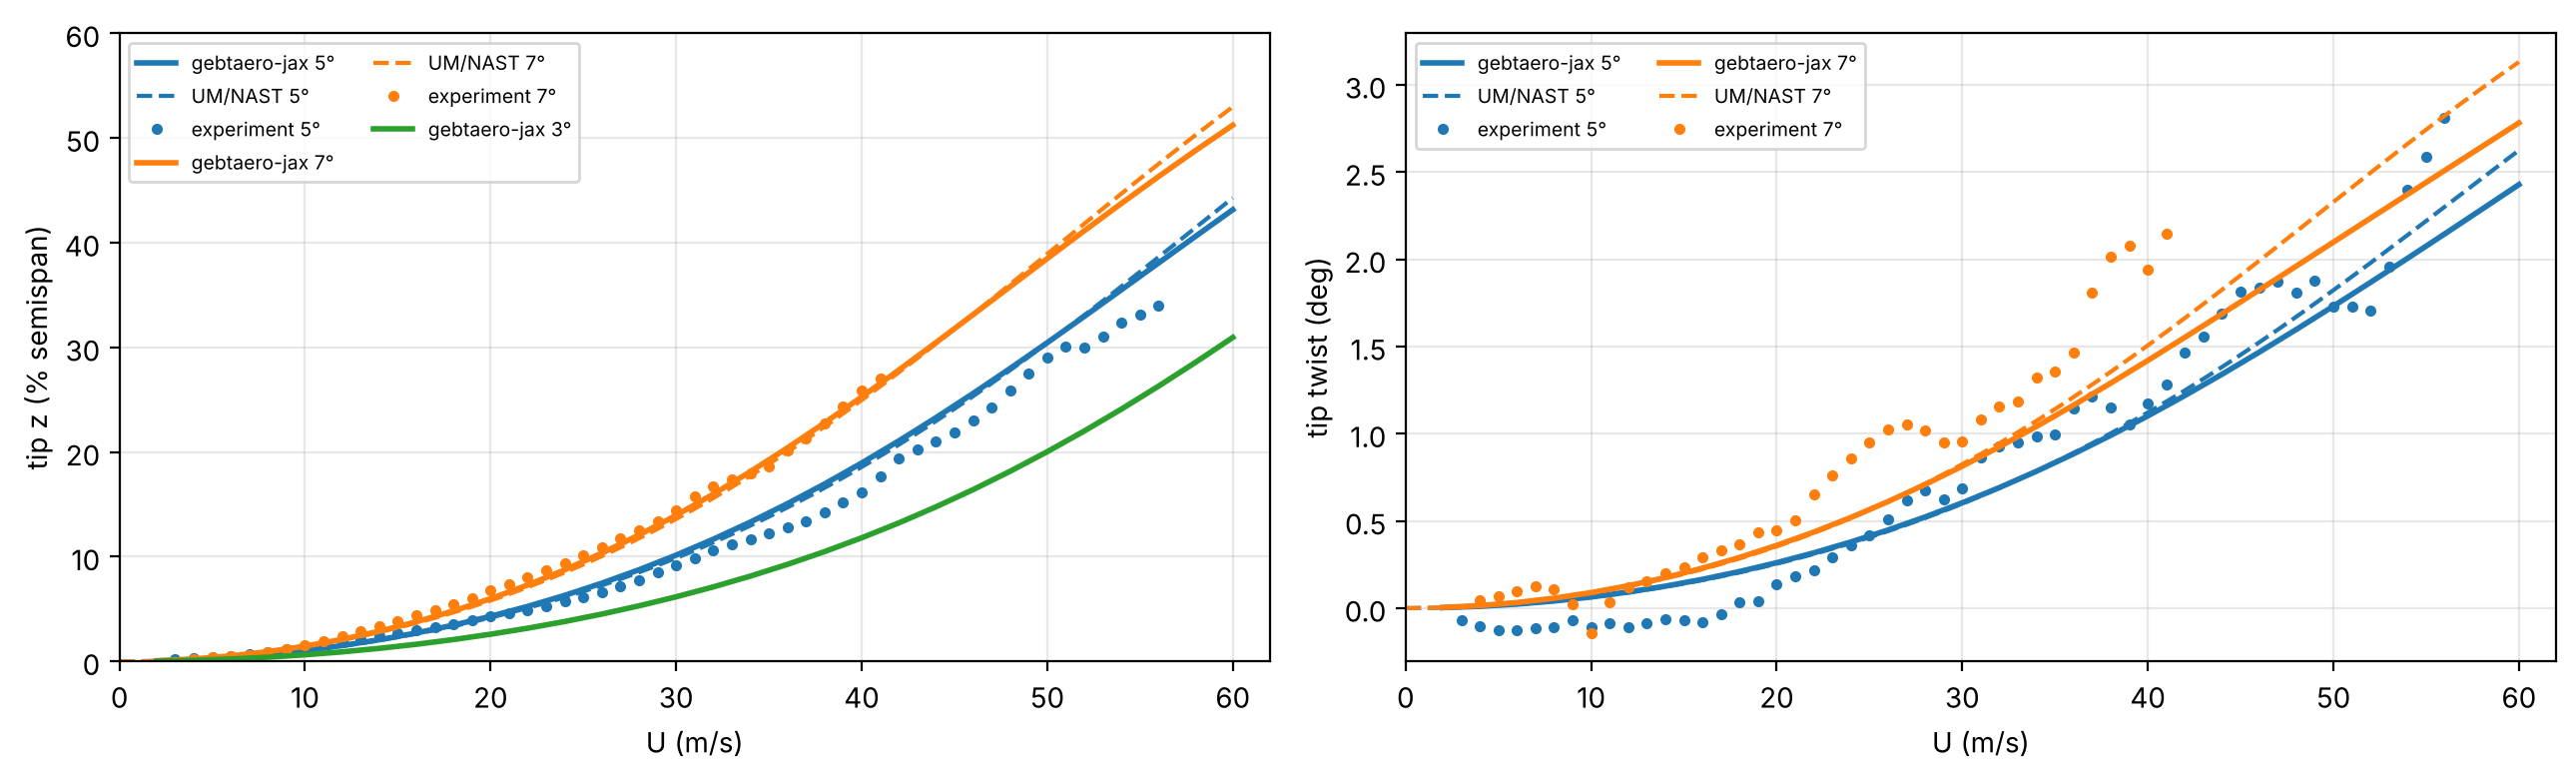

In [3]:
def static_sweep(alpha, Vs):
    x, out = None, []
    for V in Vs:
        m, f = wing.build(V=V, alpha_deg=alpha)
        x = gx.solve_static(m, f, x0=x, n_load_steps=1 if x is not None else 3)
        out.append((V, wing.tip_z_percent(m, x), wing.tip_twist_deg(m, x)))
    return np.array(out)

Vs = np.arange(2.0, 62.0, 2.0)
t0 = time.time()
sweeps = {a: static_sweep(a, Vs) for a in (3, 5, 7)}
print(f"3 sweeps x {len(Vs)} speeds in {time.time() - t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for i, a in enumerate((5, 7)):
    s, um, ex = sweeps[a], load_reference(f"umnast_static_aoa{a}.txt"), load_reference(f"exp_static_aoa{a}_disp.txt")
    axs[0].plot(s[:, 0], s[:, 1], "-", color=f"C{i}", lw=2, label=f"gebtaero-jax {a}°")
    axs[0].plot(um[:, 0], um[:, 1], "--", color=f"C{i}", label=f"UM/NAST {a}°")
    axs[0].plot(ex[:, 0], ex[:, 1], "o", color=f"C{i}", ms=3, label=f"experiment {a}°")
    ext = load_reference(f"exp_static_aoa{a}_twist.txt")
    axs[1].plot(s[:, 0], s[:, 2], "-", color=f"C{i}", lw=2, label=f"gebtaero-jax {a}°")
    axs[1].plot(um[:, 0], um[:, 4], "--", color=f"C{i}", label=f"UM/NAST {a}°")
    axs[1].plot(ext[:, 0], ext[:, 1], "o", color=f"C{i}", ms=3, label=f"experiment {a}°")
axs[0].plot(sweeps[3][:, 0], sweeps[3][:, 1], "-", color="C2", lw=2, label="gebtaero-jax 3°")
axs[0].set_xlim(0, 62); axs[0].set_ylim(0, 60); axs[0].set_xlabel("U (m/s)"); axs[0].set_ylabel("tip z (% semispan)"); axs[0].legend(fontsize=7, ncol=2)
axs[1].set_xlim(0, 62); axs[1].set_xlabel("U (m/s)"); axs[1].set_ylabel("tip twist (deg)"); axs[1].legend(fontsize=7, ncol=2)
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout()
for a in (5, 7):
    um = load_reference(f"umnast_static_aoa{a}.txt"); s = sweeps[a]
    for V in (30, 50):
        print(f"AoA {a}°, U = {V} m/s: tip z = {np.interp(V, s[:, 0], s[:, 1]):5.1f} %  (UM/NAST {np.interp(V, um[:, 0], um[:, 1]):5.1f} %)")

Deflections match UM/NAST within about 1 % of semispan up to 50 % deflection and follow the experiment (whose irregularities come from
wing vibrations and hysteresis during the tests). The twist is slightly lower at the highest speeds: our strip model has its
aerodynamic centre at the quarter chord and ignores the small moment-slope correction of the data set.

## 3. Migration of the wind-off frequencies — tracked modes
At each speed (7° root AoA) the structure is linearised about its deformed equilibrium with the aerodynamics removed. Labels are kept by
**step-to-step MAC tracking** (`tk.track` + `tk.reference_from_tracked`): each step's modes are paired with the previous step's by optimal
assignment. A single comparison with the *undeformed* shapes fails here: at 50 % deflection, torsion and in-plane bending have rotated into
each other and the MAC with the undeformed shapes drops below 0.5.

1st IP / 3rd OOP: closest at 8.7 % semispan (gap 0.72 Hz, min step MAC 0.91) — paper: ~10 %
1st torsion / 2nd OOP: closest at 27.8 % semispan (gap 0.50 Hz, min step MAC 0.72) — paper: ~29 %


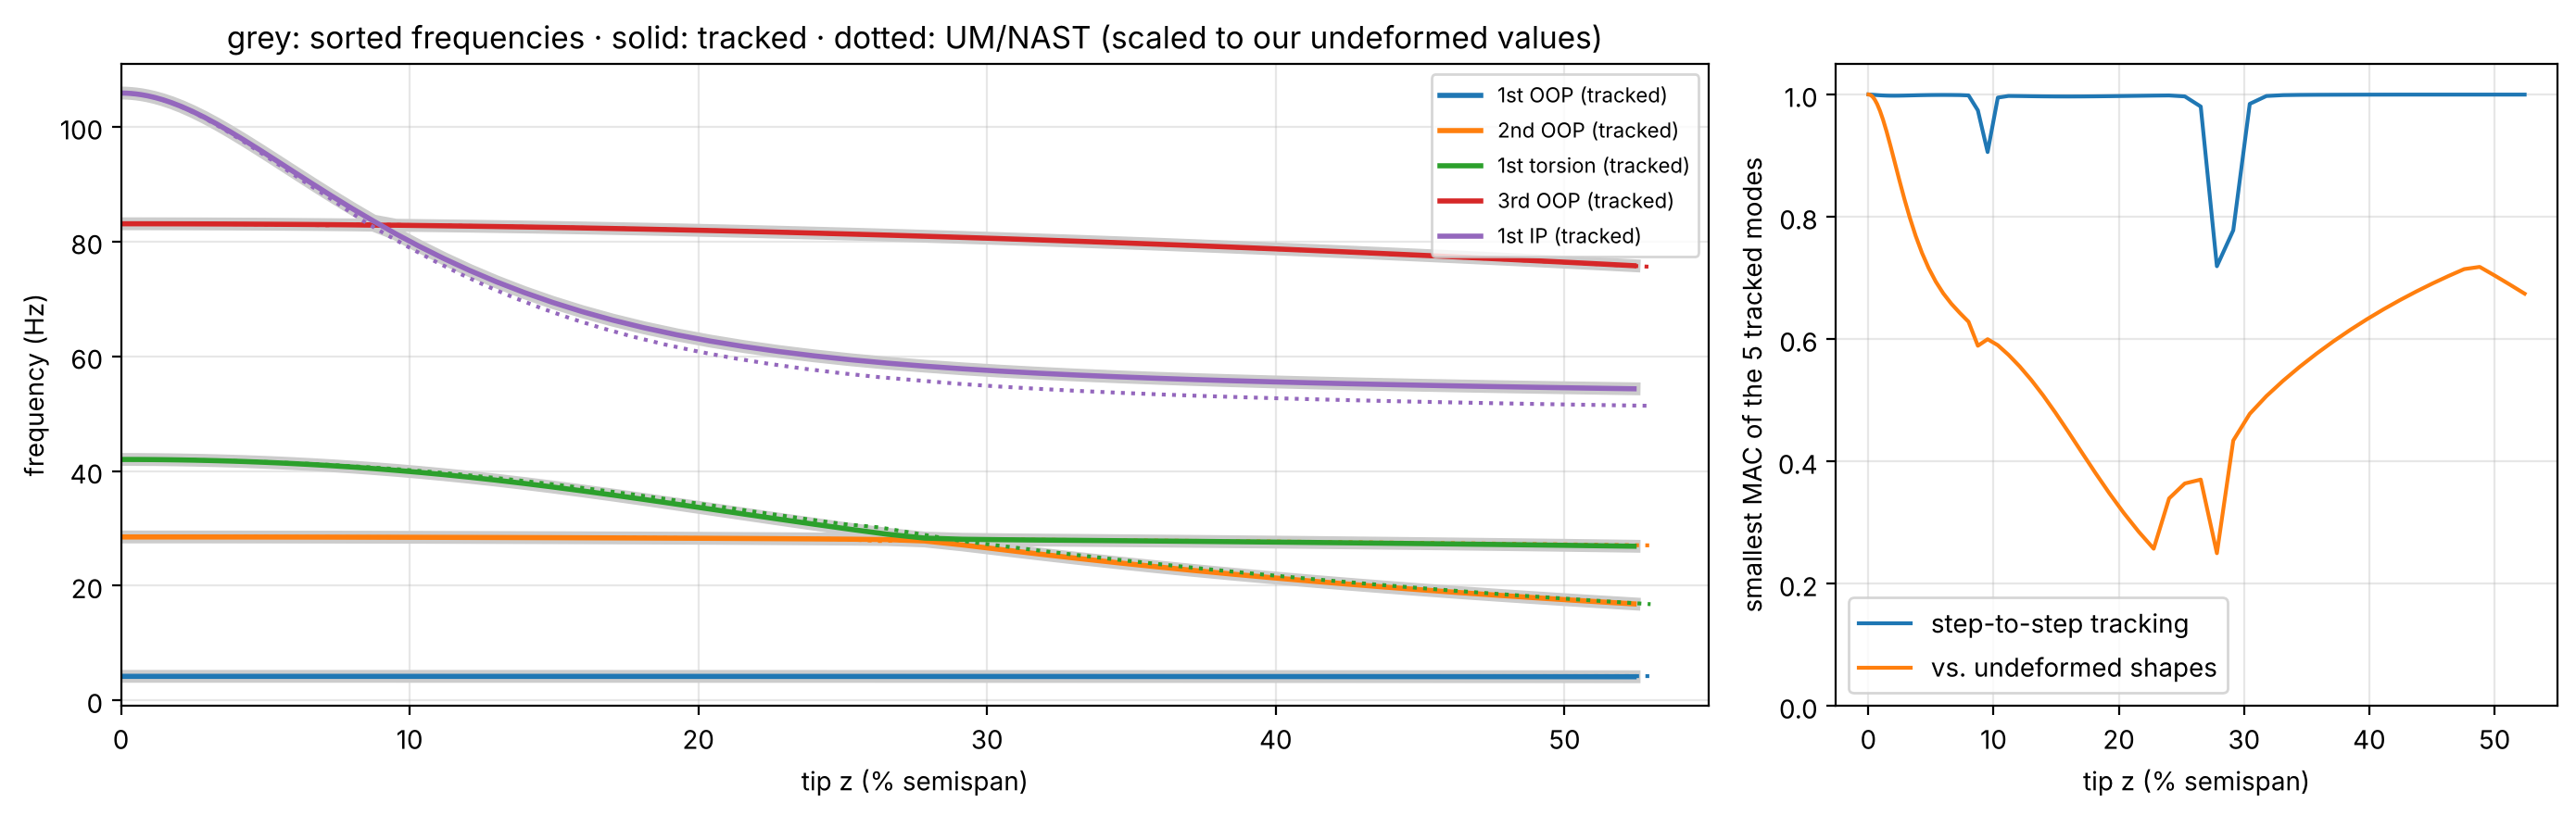

In [4]:
ref = tk.reference_modes(m0, res0, 5, names)
ref_fixed = ref
x, rows = None, []
for V in np.arange(1.0, 62.0, 1.0):
    m, f = wing.build(V=V, alpha_deg=7.0)
    x = gx.solve_static(m, f, x0=x, n_load_steps=1 if x is not None else 3)
    r = gx.modal_analysis(m0, f0, gx.convert_state(x, m, m0))
    tr = tk.track(m0, r, ref, fmax_hz=300.0); ref = tk.reference_from_tracked(m0, tr, names)
    fixed = tk.track(m0, r, ref_fixed, fmax_hz=300.0)
    rows.append((wing.tip_z_percent(m, x), *tr.freq_hz, *np.sort(r.freq_hz[r.oscillatory()])[:5], tr.mac.min(), fixed.mac.min()))
rows = np.array(rows)
um = load_reference("umnast_modal_deformed_aoa7.txt")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
axs[0].plot(rows[:, 0], rows[:, 6:11], color="0.8", lw=5)
for k in range(5):
    axs[0].plot(rows[:, 0], rows[:, 1 + k], color=f"C{k}", lw=2, label=f"{names[k]} (tracked)")
    axs[0].plot(um[:, 1], um[:, 2 + k] * f_ours[k] / um[0, 2 + k], ":", color=f"C{k}")
axs[0].set_xlabel("tip z (% semispan)"); axs[0].set_ylabel("frequency (Hz)"); axs[0].set_xlim(0, 55); axs[0].legend(fontsize=8)
axs[0].set_title("grey: sorted frequencies · solid: tracked · dotted: UM/NAST (scaled to our undeformed values)")
axs[1].plot(rows[:, 0], rows[:, 11], label="step-to-step tracking"); axs[1].plot(rows[:, 0], rows[:, 12], label="vs. undeformed shapes")
axs[1].set_xlabel("tip z (% semispan)"); axs[1].set_ylabel("smallest MAC of the 5 tracked modes"); axs[1].legend(); axs[1].set_ylim(0, 1.05)
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout()
def meeting(i, j):
    """Tip deflection where tracked modes i and j are closest in frequency, and the smallest step-to-step MAC there."""
    k = int(np.argmin(np.abs(rows[:, 1 + i] - rows[:, 1 + j])))
    return rows[k, 0], abs(rows[k, 1 + i] - rows[k, 1 + j]), rows[max(k - 2, 0):k + 3, 11].min()
for (i, j), paper in (((4, 3), "~10 %"), ((2, 1), "~29 %")):
    z, df, mac = meeting(i, j)
    print(f"{names[i]} / {names[j]}: closest at {z:.1f} % semispan (gap {df:.2f} Hz, min step MAC {mac:.2f}) — paper: {paper}")

The two coalescences that drive the Pazy behaviour appear where the workshop found them, but they are of different kinds — the
distinction of notebook 08:

* **1st in-plane / 3rd out-of-plane (≈ 9 %)**: a *crossing*. The step MAC dips only briefly (to ≈ 0.9) and recovers; tracking keeps each label, in-plane bending continues down past 3rd OOP.
* **1st torsion / 2nd out-of-plane (≈ 28 %)**: a *veering*. The step-to-step MAC drops to ≈ 0.7: the shapes genuinely mix — this coupling is
  exactly the hump-mode mechanism. Beyond it, shape-based labels follow the *shapes*, so our "2nd OOP" is the falling branch and our "1st
  torsion" the flat one, while Fig. 14 of the LDWG paper labels branches by frequency continuity (torsion falling). Neither labelling is
  wrong; at a veering no unique one exists. The frequencies themselves agree.

(The UM/NAST data set used for the dotted curves starts from slightly different undeformed frequencies, 4.03 / 27.9 / 38.6 / 82.6 /
101.8 Hz, so its curves are scaled to our undeformed values to compare the *migration*; its branches follow frequency continuity.)

## 4. Hump-mode flutter
For a fixed root AoA, the speed is swept; at every speed the nonlinear equilibrium is solved (continuation) and the aeroelastic system
— beam + Peters inflow — is linearised about it. Growth rate of the least-stable oscillatory root between 10 and 60 Hz (the hump mode);
the second instability (1st torsion + 1st OOP, above 70 m/s) is outside this band.

V-g curves at 0° and 5° in 44 s
AoA 0°: {}
AoA 5°: {'onset': '43.70 m/s, 29.8 Hz, tip 22.9 %', 'offset': '47.79 m/s, 27.7 Hz, tip 27.7 %'}


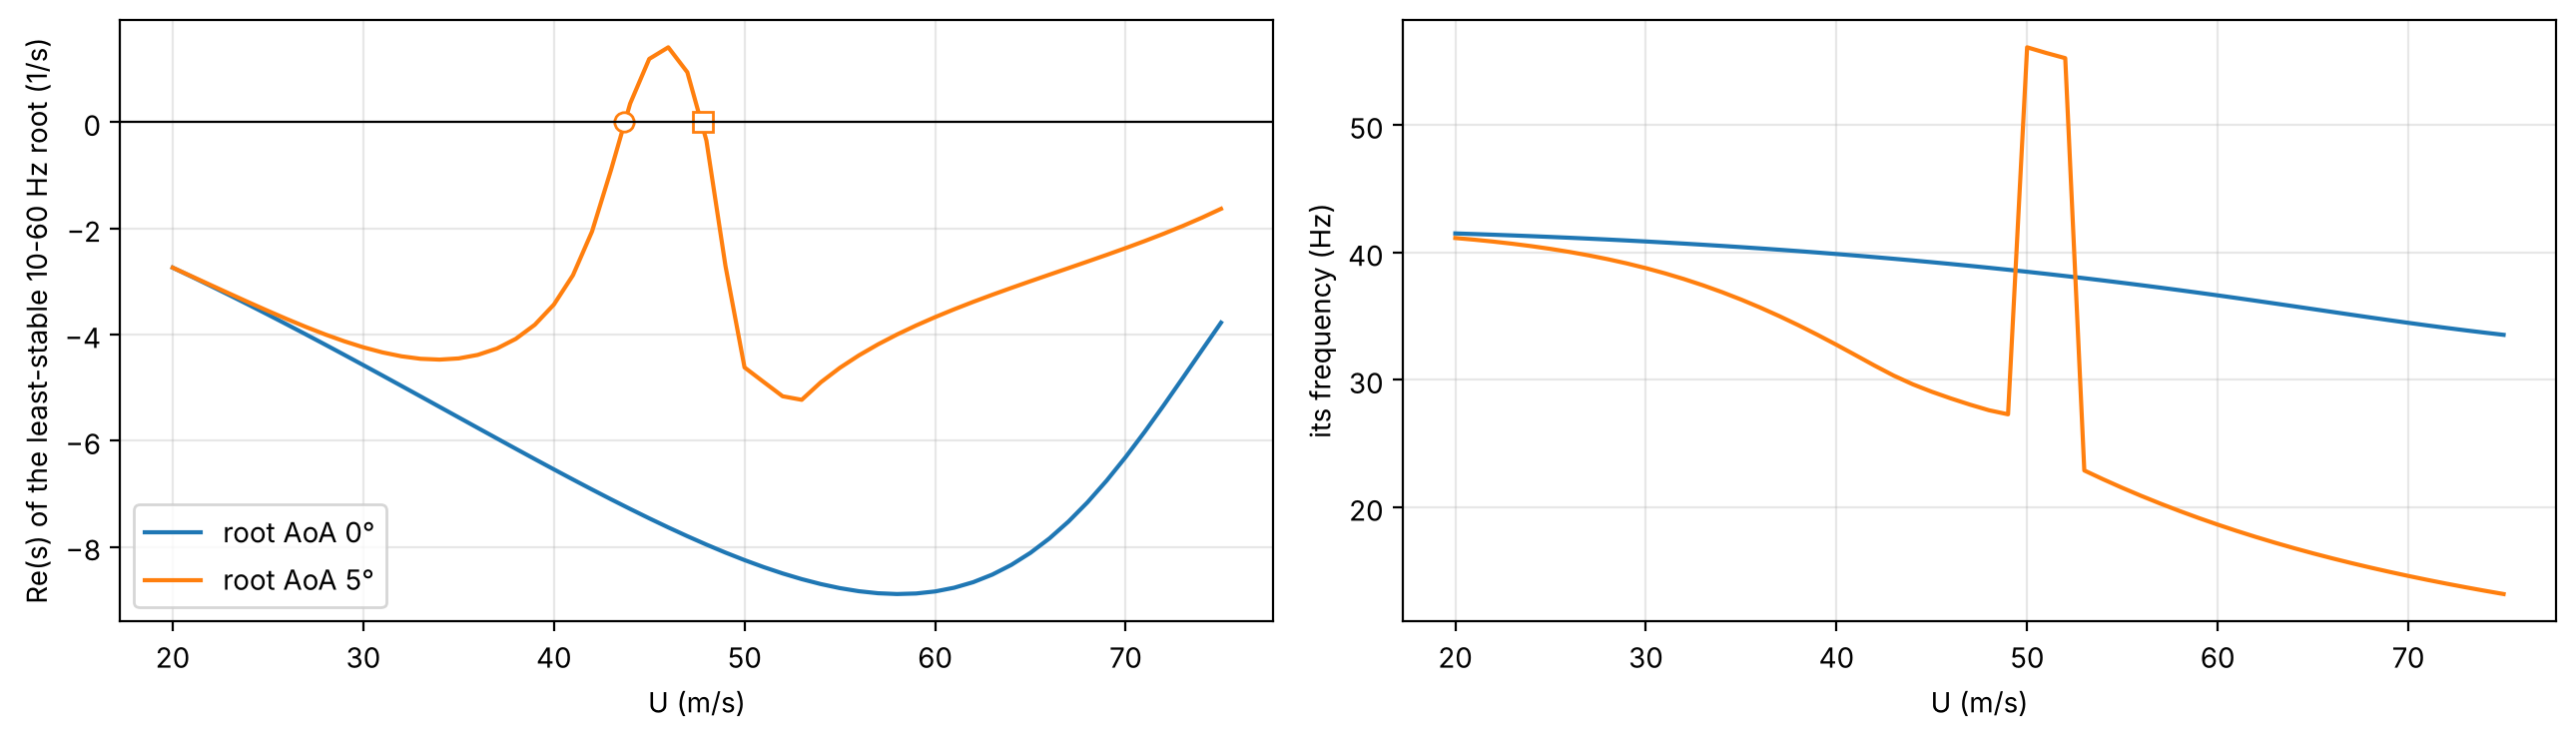

In [5]:
def growth(alpha, V, x0=None):
    m, f = wing.build(V=V, alpha_deg=alpha)
    x = gx.solve_static(m, f, x0=x0, n_load_steps=1 if x0 is not None else 3)
    r = gx.modal_analysis(m, f, x)
    i = r.oscillatory(); i = i[(r.freq_hz[i] > 10) & (r.freq_hz[i] < 60)]
    j = i[np.argmax(r.eigvals.real[i])]
    return r.eigvals.real[j], r.freq_hz[j], x, wing.tip_z_percent(m, x)

def hump(alpha, Vs):
    x, g = None, []
    for V in Vs:
        s, fr, x, z = growth(alpha, V, x); g.append((V, s, fr, z))
    g = np.array(g); out = {}
    for k in np.where(np.diff(np.sign(g[:, 1])) != 0)[0]:
        kind = "onset" if g[k, 1] < 0 else "offset"
        if kind in out: continue
        _, _, xk, _ = growth(alpha, g[k, 0])
        Vc = scipy.optimize.brentq(lambda v: growth(alpha, v, xk)[0], g[k, 0], g[k + 1, 0], xtol=1e-3)
        s, fr, _, z = growth(alpha, Vc, xk)
        out[kind] = (Vc, fr, z)
    return g, out

t0 = time.time()
curves = {a: hump(a, np.arange(20.0, 76.0, 1.0)) for a in (0, 5)}
print(f"V-g curves at 0° and 5° in {time.time() - t0:.0f} s")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for i, a in enumerate((0, 5)):
    g, out = curves[a]
    axs[0].plot(g[:, 0], g[:, 1], color=f"C{i}", label=f"root AoA {a}°"); axs[1].plot(g[:, 0], g[:, 2], color=f"C{i}")
    for kind, (Vc, fr, z) in out.items():
        axs[0].plot(Vc, 0, "o" if kind == "onset" else "s", color=f"C{i}", ms=7, mfc="w")
axs[0].axhline(0, color="k", lw=0.8); axs[0].set_xlabel("U (m/s)"); axs[0].set_ylabel("Re(s) of the least-stable 10-60 Hz root (1/s)"); axs[0].legend()
axs[1].set_xlabel("U (m/s)"); axs[1].set_ylabel("its frequency (Hz)")
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout()
for a in (0, 5):
    print(f"AoA {a}°:", {k: f"{v[0]:.2f} m/s, {v[1]:.1f} Hz, tip {v[2]:.1f} %" for k, v in curves[a][1].items()})

At 0° the undeformed wing stays stable up to 75 m/s (its damping only dips); at 5° the deformed wing develops a sharp hump
between about 43 and 48 m/s — the mechanism of Fig. 4 and Fig. 15 of the LDWG paper. Now the boundaries for root AoA from 1° to 7°:

In [6]:
alphas = [1, 2, 3, 4, 5, 6, 7]
t0 = time.time()
bounds = {a: hump(a, np.arange(30.0, 76.0, 2.0))[1] for a in alphas}
print(f"onset/offset for {len(alphas)} angles in {time.time() - t0:.0f} s\n")
um_on, um_off = load_reference("umnast_flutter_onset_vs_aoa.txt"), load_reference("umnast_flutter_offset_vs_aoa.txt")
print(f"{'AoA':>4} | {'onset':>7} {'UM/NAST':>8} {'LDWG mean':>10} {'exp':>5} | {'offset':>7} {'UM/NAST':>8} {'LDWG mean':>10} {'exp':>5} | {'f_onset':>7} {'tip':>6}")
for a in alphas:
    b = bounds[a]; on = b.get("onset", (np.nan,) * 3); off = b.get("offset", (np.nan,) * 3)
    u1 = np.interp(a, um_on[:, 0], um_on[:, 1], left=np.nan); u2 = np.interp(a, um_off[:, 0], um_off[:, 1], left=np.nan)
    l1 = LDWG["onset"].get(a, (np.nan,))[0]; l2 = LDWG["offset"].get(a, (np.nan,))[0]
    print(f"{a:4d} | {on[0]:7.2f} {u1:8.2f} {l1:10.1f} {EXP['onset'].get(a, np.nan):5.0f} | {off[0]:7.2f} {u2:8.2f} {l2:10.1f} "
          f"{EXP['offset'].get(a, np.nan):5.0f} | {on[1]:7.1f} {on[2]:5.1f}%")

onset/offset for 7 angles in 80 s

 AoA |   onset  UM/NAST  LDWG mean   exp |  offset  UM/NAST  LDWG mean   exp | f_onset    tip
   1 |   65.78      nan        nan   nan |   73.68      nan        nan   nan |    31.3  16.1%
   2 |   56.73      nan        nan   nan |   63.33      nan        nan   nan |    30.8  19.3%
   3 |   50.99    50.58       47.7    49 |   56.56    55.35       58.4    55 |    30.4  21.0%
   4 |   46.87    46.37        nan   nan |   51.62    50.45        nan   nan |    30.1  22.1%
   5 |   43.70    43.14       41.8    43 |   47.79    46.70       48.6    48 |    29.8  22.9%
   6 |   41.16    40.58        nan   nan |   44.71    43.68        nan   nan |    29.6  23.6%
   7 |   39.07    38.49       37.9    38 |   42.15    41.19       43.5   nan |    29.5  24.1%


Text(0.5, 1.0, 'Pazy wing: first flutter region (hump mode)')

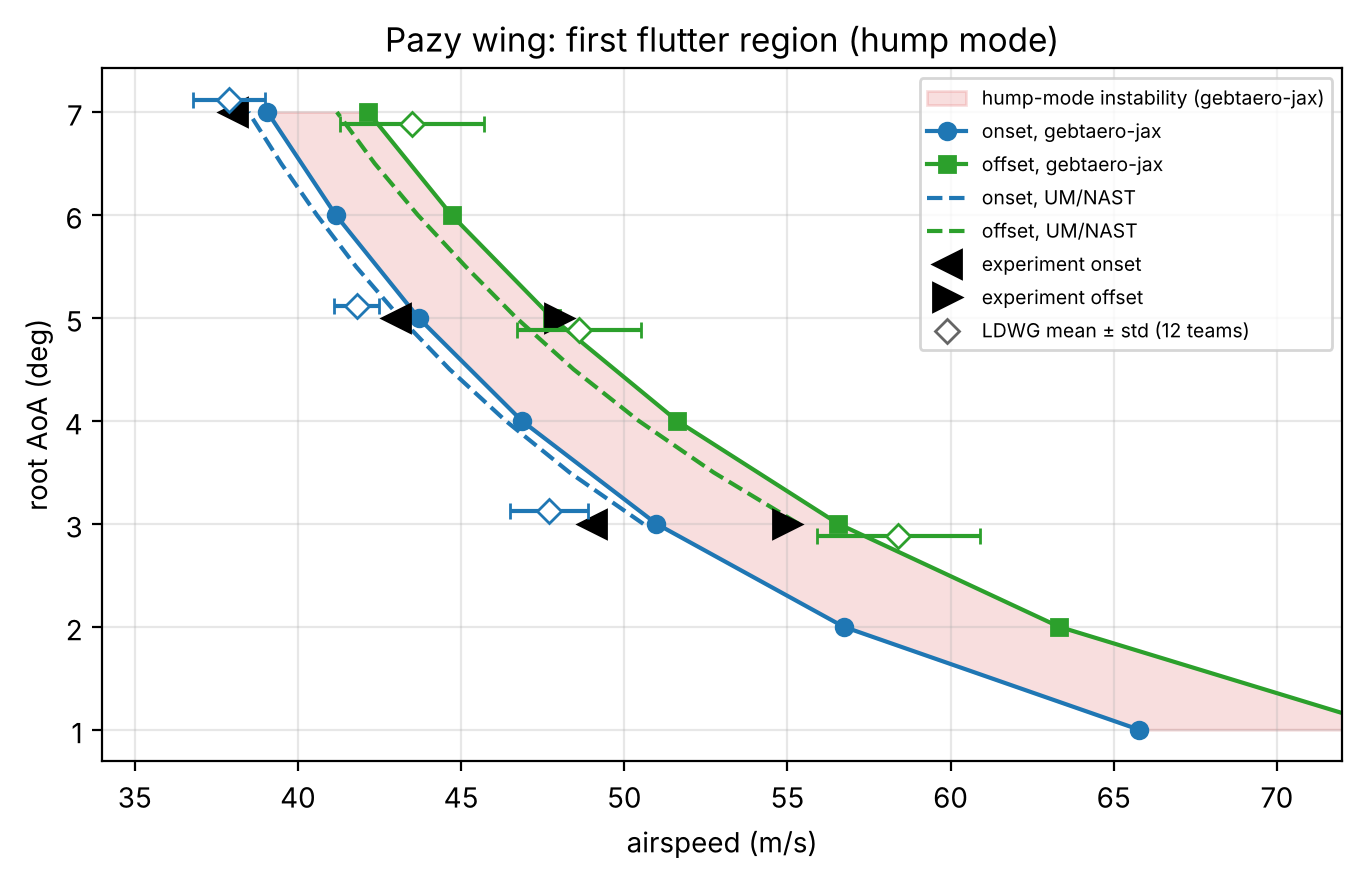

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
on = np.array([[a, bounds[a]["onset"][0]] for a in alphas if "onset" in bounds[a]])
off = np.array([[a, bounds[a]["offset"][0]] for a in alphas if "offset" in bounds[a]])
ax.fill_betweenx(on[:, 0], on[:, 1], np.interp(on[:, 0], off[:, 0], off[:, 1]), color="C3", alpha=0.15, label="hump-mode instability (gebtaero-jax)")
ax.plot(on[:, 1], on[:, 0], "C0o-", label="onset, gebtaero-jax"); ax.plot(off[:, 1], off[:, 0], "C2s-", label="offset, gebtaero-jax")
ax.plot(um_on[:, 1], um_on[:, 0], "C0--", label="onset, UM/NAST"); ax.plot(um_off[:, 1], um_off[:, 0], "C2--", label="offset, UM/NAST")
for kind, mk, c in (("onset", "<", "C0"), ("offset", ">", "C2")):
    pts = EXP[kind]; ax.plot(list(pts.values()), list(pts.keys()), mk, color="k", ms=10, label=f"experiment {kind}")
    for a, (mu, sd) in LDWG[kind].items():
        ax.errorbar(mu, a + (0.12 if kind == "onset" else -0.12), xerr=sd, fmt="D", color=c, mfc="w", ms=6, capsize=3)
ax.plot([], [], "D", color="0.4", mfc="w", label="LDWG mean ± std (12 teams)")
ax.set_xlabel("airspeed (m/s)"); ax.set_ylabel("root AoA (deg)"); ax.set_xlim(34, 72); ax.legend(fontsize=7, loc="upper right"); ax.grid(alpha=.3)
ax.set_title("Pazy wing: first flutter region (hump mode)")

Onset speeds fall within 0.6 m/s of UM/NAST (same beam data and strip aerodynamics) and within 1–2 m/s of the experiment, inside the
workshop's spread; offsets are slightly above the experiment, as for most eigenvalue-based entries (the experimental offset results from a
subcritical bifurcation that linearisation cannot capture — Ritter et al., §VI).

## 5. Exact sensitivities of the onset speed and a first-order uncertainty estimate
`flutter_speed_and_grad(..., deformed=True)` differentiates the onset speed through the nonlinear equilibrium (implicit function theorem)
and the flutter eigenproblem (eigen-adjoint). Parameters are scale factors on torsion, out-of-plane and in-plane stiffness, inertia and lift
slope.

In [8]:
P0 = {k: jnp.asarray(1.0) for k in ["GJ", "EI_oop", "EI_ip", "mass", "cla"]}
rows_s = []
for a in (3, 5, 7):
    build = lambda p, V, a=a: wing.build(p, V, a)
    V0 = bounds[a]["onset"][0]
    t0 = time.time()
    r = gx.flutter_speed_and_grad(build, P0, V0 - 4, V0 + 2, n_grid=4, fmax_hz=60.0, deformed=True, tol=1e-6, n_load_steps=3)
    rows_s.append((a, r.point.velocity, {k: float(v) for k, v in r.dV_dparams.items()}, time.time() - t0))
print(f"{'AoA':>4} {'V_onset':>8} | " + " ".join(f"{k:>8s}" for k in P0) + "   (dV/d ln p, m/s)")
for a, V, g, t in rows_s:
    print(f"{a:4d} {V:8.2f} | " + " ".join(f"{g[k]:8.2f}" for k in P0) + f"   [{t:.0f} s]")

 AoA  V_onset |       GJ   EI_oop    EI_ip     mass      cla   (dV/d ln p, m/s)
   3    50.99 |    22.31     2.65     0.82    -1.08   -27.92   [22 s]
   5    43.70 |    18.81     2.42     0.80    -0.93   -23.49   [17 s]
   7    39.07 |    16.64     2.24     0.77    -0.86   -20.77   [17 s]


Torsional stiffness and lift slope dominate. With independent 1-σ uncertainties of 5 % on the stiffnesses and inertia (beam extraction from
the built-up FEM, foil pre-tension) and 5 % on the lift slope (strip corrections), the first-order standard deviation of the onset speed is
$\sigma_V = \big(\sum_k (\partial V/\partial \ln p_k\ \sigma_k)^2\big)^{1/2}$:

In [9]:
sig = {"GJ": 0.05, "EI_oop": 0.05, "EI_ip": 0.05, "mass": 0.05, "cla": 0.05}
for a, V, g, _ in rows_s:
    sV = np.sqrt(sum((g[k] * sig[k]) ** 2 for k in sig))
    print(f"AoA {a}°: V_onset = {V:.1f} ± {sV:.1f} m/s (1σ)   — LDWG spread {LDWG['onset'][a][1]:.1f} m/s, experiment {EXP['onset'][a]} m/s")

AoA 3°: V_onset = 51.0 ± 1.8 m/s (1σ)   — LDWG spread 1.2 m/s, experiment 49 m/s
AoA 5°: V_onset = 43.7 ± 1.5 m/s (1σ)   — LDWG spread 0.7 m/s, experiment 43 m/s
AoA 7°: V_onset = 39.1 ± 1.3 m/s (1σ)   — LDWG spread 1.1 m/s, experiment 38 m/s


## 6. Soft flutter in the time domain
Inside the hump at 5° (45 m/s) a small tip perturbation grows slowly; above the offset speed (50 m/s) it decays. The nonlinear simulation
starts from the static equilibrium. Without stall, nothing limits the growth: the limit-cycle amplitudes seen in the tunnel are set by
aerodynamic nonlinearities that strip theory does not model.

Text(0.5, 1.0, '5° root AoA: inside the hump (45 m/s) vs. beyond its offset (50 m/s)')

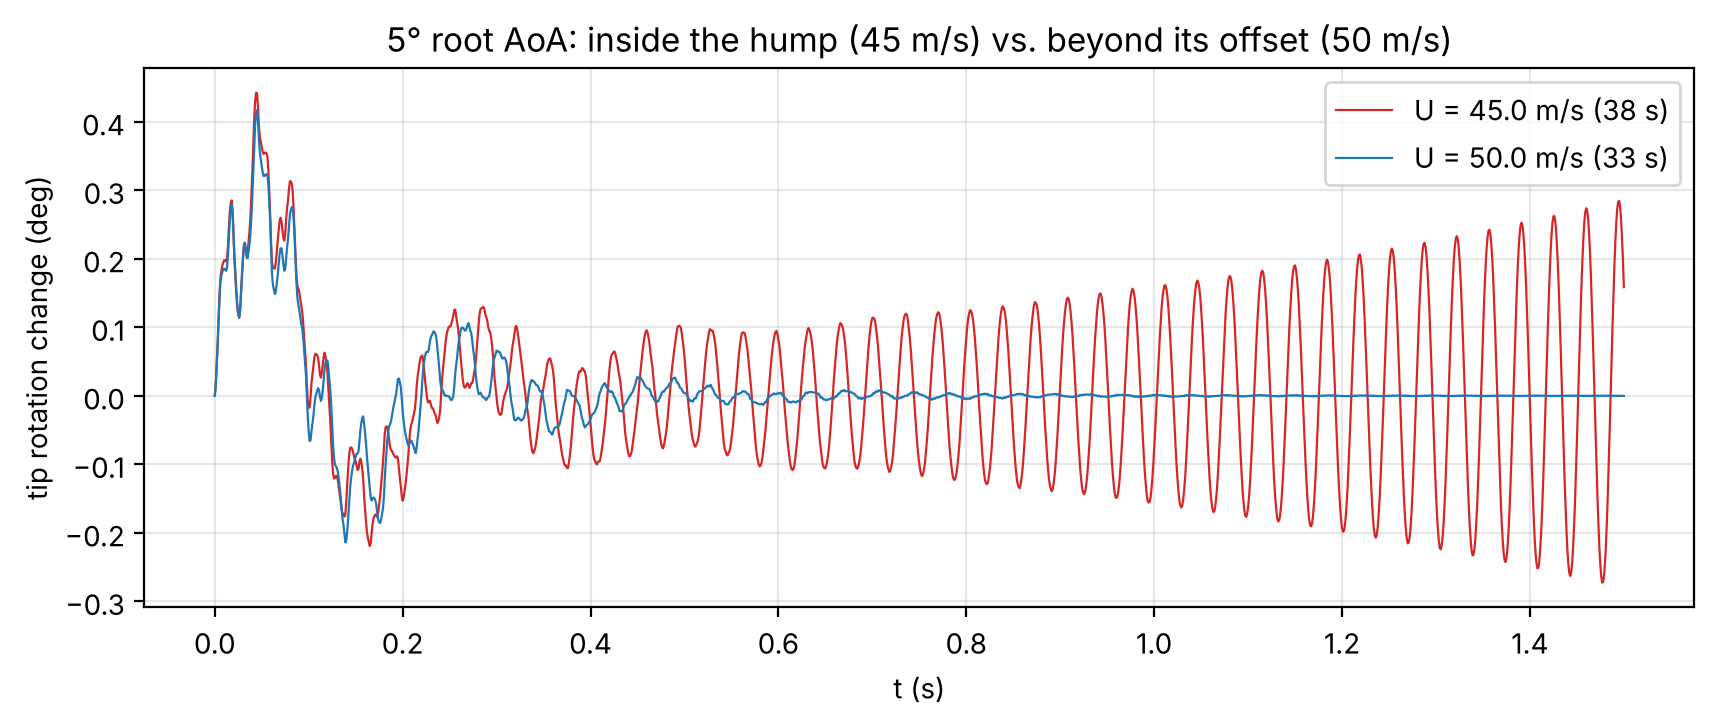

In [10]:
def kick(t, fl):
    return fl.replace(tip_force=jnp.array([0.0, 0.0, -jnp.where(t < 0.005, 2.0, 0.0)]))
fig, ax = plt.subplots(figsize=(10, 3.5))
for V, c in ((45.0, "C3"), (50.0, "C0")):
    m, f = wing.build(V=V, alpha_deg=5.0)
    xs = gx.solve_static(m, f, n_load_steps=4)
    t0 = time.time(); h = gx.simulate(m, f, t_end=1.5, dt=0.001, x0=xs, flight_fn=kick, rho_inf=0.95)
    tw = np.degrees(gx.rotations.rodrigues_to_angle(jnp.asarray(h.tip()[:, 3:]))) - np.degrees(float(gx.rotations.rodrigues_to_angle(xs[-3:])))
    ax.plot(h.t, tw, c, lw=0.8, label=f"U = {V} m/s ({time.time() - t0:.0f} s)")
ax.set_xlabel("t (s)"); ax.set_ylabel("tip rotation change (deg)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("5° root AoA: inside the hump (45 m/s) vs. beyond its offset (50 m/s)")

## Summary
* The Riso & Cesnik equivalent beam, used with GEBT's mixed formulation, reproduces UM/NAST's frequencies (0.3 %), static deflections
  up to 50 % semispan, the eigenvalue crossings that drive the hump mode, and the hump onset/offset speeds — i.e. the A-1 entry of the
  LDWG — with a different geometrically exact formulation and an independent code.
* Step-to-step MAC tracking is necessary at these deflections: comparing with the undeformed shapes loses the torsion and in-plane labels.
* AD gives exact onset-speed sensitivities through the nonlinear equilibrium in seconds; a 5 % parameter uncertainty already produces a
  1σ spread of 1.3–1.8 m/s, larger than the 0.7–1.2 m/s scatter between the workshop teams.

**Limits.** Strip theory with the spanwise lift slope of the data set (moment-slope correction not used), no stall (no LCO, no
subcritical offset), no gravity (vertical mounting), the skin model without tip mass only.